In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

# setting pandas display options
pd.set_option("display.float_format", lambda x: f"{x:.5g}")
pd.set_option("display.max_columns", None)


# versions
print(sys.executable)
print('pandas', pd.__version__)

/Users/qusaislaptop/miniconda3/envs/fnol_env/bin/python
pandas 3.1.0


In [3]:
from pathlib import Path
import sys

# Locate the project root and ensure the src directory is in the sys.path
project_root = Path.cwd()
while project_root != project_root.parent and not (project_root / "src").is_dir():
    project_root = project_root.parent

src_dir = project_root / "src"
if not src_dir.is_dir():
    raise FileNotFoundError("Could not locate the src directory from the notebook's working directory.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

for path in sorted(src_dir.rglob("*")):
    kind = "DIR " if path.is_dir() else "FILE"
    # print(f"{kind} {path.relative_to(project_root)}")

# import helper functions
from src.data.loaders import load_excel
from src.utils.utils import replace_abnormal_entries

# Reading The Data 

In [4]:
df = load_excel("/Users/qusaislaptop/Projects/data_science/hastings_case_study/data/raw/Data_Scientist_Interview_FNOL_Data.xlsx")
df.head()

,claim number,date_of_loss,notifier,loss_code,loss_description,notification_period,inception_to_loss,location_of_incident,weather_conditions,vehicle_mobile,time_hour,main_driver,ph_considered_tp_at_fault,vechile_registration_present,incident_details_present,injury_details_present,tp_type_insd_pass_back,tp_type_insd_pass_front,tp_type_driver,tp_type_pass_back,tp_type_pass_front,tp_type_bike,tp_type_cyclist,tp_type_pass_multi,tp_type_pedestrian,tp_type_other,tp_type_nk,tp_injury_whiplash,tp_injury_traumatic,tp_injury_fatality,tp_injury_unclear,tp_injury_nk,tp_region_eastang,tp_region_eastmid,tp_region_london,tp_region_north,tp_region_northw,tp_region_outerldn,tp_region_scotland,tp_region_southe,tp_region_southw,tp_region_wales,tp_region_westmid,tp_region_yorkshire,incurred,capped incurred
0,1,2003-04-15,PH,LD003,Head on collision,22,13,Main Road,NORMAL,Y,10,Other,n/k,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1,2,2003-04-20,CNF,LD003,Head on collision,1,9,Main Road,WET,Y,18,Other,n/k,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,2801.3,2801.3
2,3,2003-04-24,CNF,LD003,Head on collision,5,17,Main Road,WET,Y,16,Y,n/k,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1220.9,1220.9
3,4,2003-05-13,CNF,LD003,Head on collision,1,23,Main Road,N/K,Y,14,Other,n/k,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,3529.9,3529.9
4,5,2003-06-11,CNF,LD003,Head on collision,1,48,Other,N/K,N,9,Other,n/k,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,3156,3156


# EDA

In [5]:
###### Features categories

#### Claim related features
# claim number 
# loss descritpion
# notifier
# loss code 
# injury details present 
# incident details present 

### date features 
# date of loss
# inception to loss 
# notification period 
# time hour 

### location data 
# location of incident 

### driver data 
# main driver 

### vehicle data 
# vehicle regestiration present 
# vehicle mobile 

### weather data 
# weather conditions 

### TP data 
# rest of features  

In [6]:
print(df.shape)

(7691, 46)


In [7]:
# noticed some abnormal entries in the data like N/k, n/k, #
# will replace them with np.nan
print(df['ph_considered_tp_at_fault'].value_counts(), '\n')
print(df['location_of_incident'].value_counts())

# apply the function to replace abnormal entries
df = replace_abnormal_entries(df)


ph_considered_tp_at_fault
N      4855
n/k    2654
Y       181
#         1
Name: count, dtype: int64 

location_of_incident
Minor Road        4249
Main Road         2702
Car Park           225
n/k                213
Other              117
Home Address       104
Not Applicable      56
Motorway            25
Name: count, dtype: int64


In [8]:
# checking null counts in each column after replacing abnormal entries
print(df.isnull().sum().sort_values(ascending=False)/df.shape[0] * 100)

ph_considered_tp_at_fault      34.521
weather_conditions             10.337
vehicle_mobile                  5.747
location_of_incident           2.7695
tp_region_northw                    0
tp_injury_whiplash                  0
tp_injury_traumatic                 0
tp_injury_fatality                  0
tp_injury_unclear                   0
tp_injury_nk                        0
tp_region_eastang                   0
tp_region_eastmid                   0
tp_region_london                    0
tp_region_north                     0
claim number                        0
tp_region_outerldn                  0
tp_type_other                       0
tp_region_scotland                  0
tp_region_southe                    0
tp_region_southw                    0
tp_region_wales                     0
tp_region_westmid                   0
tp_region_yorkshire                 0
incurred                            0
tp_type_nk                          0
tp_type_pass_multi                  0
tp_type_pede

In [9]:
df.describe(include='all').transpose()

#### notes 
# notfication period has negative values 
# tp_type_insd_pass_front is all zeros 
# tp_type_pass_multi is all zeros
# loss code and loss description have only one value
# try creating cyclical/new time based features from existing time based features 

### columns not sure what they mean 
# tp_type_insd_pass_back
# tp_type_insd_pass_back
# tp_type_driver
# tp_type_pass_back
# tp_type_pass_front


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
claim number,7691,NaN,NaN,NaN,3846,2220.3,1,1923.5,3846,5768.5,7691
date_of_loss,7691,3175,2014-05-08,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
notifier,7691,5,PH,3807,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loss_code,7691,1,LD003,7691,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loss_description,7691,1,Head on collision,7691,NaN,NaN,NaN,NaN,NaN,NaN,NaN
notification_period,7691,NaN,NaN,NaN,7.1634,39.138,-18,0,1,2,1042
inception_to_loss,7691,NaN,NaN,NaN,166.85,104.45,0,75,161,253,365
location_of_incident,7478,7,Minor Road,4249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_conditions,6896,3,NORMAL,4564,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_mobile,7249,2,Y,4046,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# dropping the following columns as they have only one value
df.drop(columns=['loss_code', 'loss_description', 'tp_type_insd_pass_front', 'tp_type_pass_multi'], inplace=True)
print("shape of df after dropping columns:", df.shape)

shape of df after dropping columns: (7691, 42)


In [11]:
# checking notification period column 
# 3 rows where the notification period is negative
print((df['notification_period'] < 0).sum(), '\n')

 # notificaiton period description > 0 
print(df[df['notification_period'] >= 0]['notification_period'].describe(), '\n')

# will impute the negative notification values with the median of the positive notification periods (median = 1)
median_notification_period = df[df['notification_period'] >= 0]['notification_period'].median()
print(f"Median notification period: {median_notification_period}", '\n')
df.loc[df['notification_period'] < 0, 'notification_period'] = median_notification_period

# checking if there are any negative notification periods left
print((df['notification_period'] < 0).sum(), '\n')

print(df['notification_period'].describe(), '\n')



3 

count     7688
mean     7.169
std     39.145
min          0
25%          0
50%          1
75%          2
max       1042
Name: notification_period, dtype: float64 

Median notification period: 1.0 

0 

count     7691
mean    7.1666
std     39.137
min          0
25%          0
50%          1
75%          2
max       1042
Name: notification_period, dtype: float64 



In [12]:
# changing dtype to datetime 
df['date_of_loss'] = pd.to_datetime(df['date_of_loss'])
# checking dtypes 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7691 entries, 0 to 7690
Data columns (total 42 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   claim number                  7691 non-null   int64         
 1   date_of_loss                  7691 non-null   datetime64[us]
 2   notifier                      7691 non-null   str           
 3   notification_period           7691 non-null   int64         
 4   inception_to_loss             7691 non-null   int64         
 5   location_of_incident          7478 non-null   str           
 6   weather_conditions            6896 non-null   str           
 7   vehicle_mobile                7249 non-null   str           
 8   time_hour                     7691 non-null   int64         
 9   main_driver                   7691 non-null   str           
 10  ph_considered_tp_at_fault     5036 non-null   str           
 11  vechile_registration_present  7691 non-nu

## The Target 

In [13]:
# 198 large loss claims above 50k 
# 1754 claims with zero incurred, claims that haven't been paid off yet 
# 48 claims with negative incurred
print(df['capped incurred'].describe(), "\n")
print(df['incurred'].describe(), "\n")

print(f"number of negative capped incurred: {(df['capped incurred'] < 0).sum()}")
print(f"number of negative incurred: {(df['incurred'] < 0).sum()}")

print(f"number of zero capped incurred: {(df['capped incurred'] == 0).sum()}")
print(f"number of zero incurred: {(df['incurred'] == 0).sum()}")

print(f"number of incurred greater than 50k: {(df['incurred'] > 50000).sum()}")

count     7691
mean    6106.9
std      11057
min     -10539
25%     24.909
50%     1237.7
75%     6258.4
max      50000
Name: capped incurred, dtype: float64 

count         7691
mean        9423.3
std          49852
min         -10539
25%         24.909
50%         1237.7
75%         6258.4
max     1.9519e+06
Name: incurred, dtype: float64 

number of negative capped incurred: 48
number of negative incurred: 48
number of zero capped incurred: 1754
number of zero incurred: 1754
number of incurred greater than 50k: 198


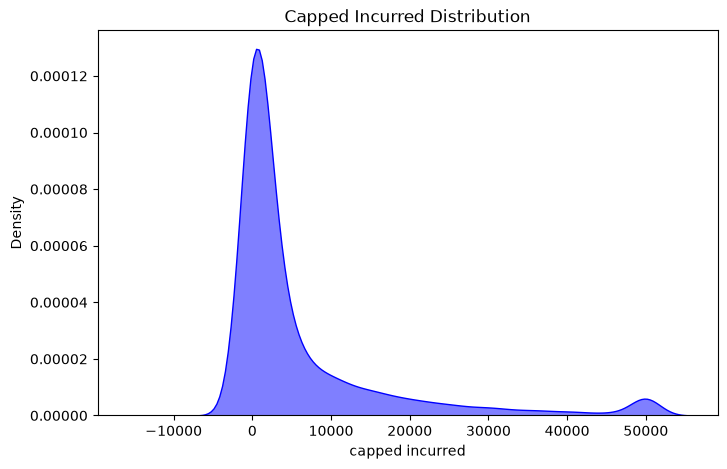

In [14]:
# plotting capped incurred distribution
plt.figure(figsize=(8,5))
sns.kdeplot(df['capped incurred'], label='Capped Incurred', shade=True, alpha=0.5,color='blue')
plt.title('Capped Incurred Distribution')
plt.show()

# Features/Target Engineering 

In [15]:
# import helper functions for feature engineering
from src.features.build_features import build_aggregate_features, build_time_features, add_targets



In [16]:
# build time based/cyclical features
df = build_time_features(df)

# build third party and region aggregate features 
df = build_aggregate_features(df)

In [17]:
df.shape

(7691, 66)

In [18]:
# adding engineered targets to the df 
df = add_targets(df)

In [19]:
df['y_capped'].describe()

count     7691
mean    6111.5
std      11054
min          0
25%     24.909
50%     1237.7
75%     6258.4
max      50000
Name: y_capped, dtype: float64

In [24]:
spearman_correlations = (
    df.select_dtypes(include="number")
    .drop(columns=["y_capped", "y_incurred", "incurred", "capped incurred", 'y_large'])
    .corrwith(df["y_capped"], method="spearman")
    .sort_values(ascending=False)
    .rename("spearman_correlation")
    .to_frame()
)

display(spearman_correlations.head(10))

,spearman_correlation
inj_flagged_n,0.51924
inj_severity_ord,0.50961
inj_per_tp,0.50651
tp_injury_whiplash,0.47254
tp_n_total,0.36217
tp_type_pass_front,0.2852
tp_injury_traumatic,0.23521
tp_type_pass_back,0.21648
tp_type_other,0.2073
tp_reg_north,0.16659


In [25]:
df.columns.tolist()

['claim number',
 'date_of_loss',
 'notifier',
 'notification_period',
 'inception_to_loss',
 'location_of_incident',
 'weather_conditions',
 'vehicle_mobile',
 'time_hour',
 'main_driver',
 'ph_considered_tp_at_fault',
 'vechile_registration_present',
 'incident_details_present',
 'injury_details_present',
 'tp_type_insd_pass_back',
 'tp_type_driver',
 'tp_type_pass_back',
 'tp_type_pass_front',
 'tp_type_bike',
 'tp_type_cyclist',
 'tp_type_pedestrian',
 'tp_type_other',
 'tp_type_nk',
 'tp_injury_whiplash',
 'tp_injury_traumatic',
 'tp_injury_fatality',
 'tp_injury_unclear',
 'tp_injury_nk',
 'tp_region_eastang',
 'tp_region_eastmid',
 'tp_region_london',
 'tp_region_north',
 'tp_region_northw',
 'tp_region_outerldn',
 'tp_region_scotland',
 'tp_region_southe',
 'tp_region_southw',
 'tp_region_wales',
 'tp_region_westmid',
 'tp_region_yorkshire',
 'incurred',
 'capped incurred',
 'loss_month',
 'loss_day_of_week',
 'loss_day_of_year',
 'loss_is_weekend',
 'loss_hour_sin',
 'loss_hou